In [1]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('fma_dataset_filtered.csv')
data.head()


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


In [3]:
data.shape

(2406, 524)

In [4]:
data.describe()

,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
count,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,...,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000,2406.000000
mean,27246.670823,0.063542,-0.082459,0.024900,-0.073564,0.010460,-0.044657,-0.062988,-0.014984,-0.065439,...,0.368378,0.050561,0.041361,0.002678,3.428497,0.036722,242.634248,114.593813,0.490342,0.349536
std,25169.208602,1.891557,1.106436,1.501832,1.098007,1.573417,1.150381,1.240372,1.421700,1.364783,...,0.164931,0.031612,0.029588,0.005184,2.852553,0.024209,238.691886,37.143449,0.186391,0.252201
min,2.000000,-1.713556,-1.651053,-1.793530,-1.601526,-1.745835,-1.558694,-1.558443,-1.690922,-1.680693,...,0.051270,0.003505,0.000000,0.000000,-1.062790,0.004279,31.000000,19.659000,0.053491,0.000077
25%,11788.250000,-0.693621,-0.689587,-0.697414,-0.699416,-0.713293,-0.695228,-0.694451,-0.683760,-0.708446,...,0.252686,0.031478,0.024414,0.000000,1.726614,0.017921,150.000000,89.524750,0.356900,0.126627
50%,19076.500000,-0.285531,-0.332003,-0.314715,-0.322115,-0.308662,-0.300797,-0.321902,-0.304667,-0.342531,...,0.369141,0.045578,0.036133,0.000000,2.648856,0.030944,196.000000,105.010000,0.477879,0.314594
75%,33714.750000,0.285472,0.212239,0.272046,0.242089,0.287923,0.245239,0.214084,0.213251,0.201312,...,0.450684,0.063127,0.051270,0.003418,4.272882,0.051037,256.000000,137.849000,0.625101,0.531563
max,124722.000000,42.851593,14.327950,20.394966,19.266939,43.405674,17.028032,30.522015,30.898539,35.876045,...,0.996094,0.488016,0.491699,0.074707,29.338261,0.210072,2926.000000,241.277000,0.961871,0.999537


In [5]:
x = data.drop(columns = ['genre', 'track_id'])
scaler = StandardScaler().set_output(transform="pandas")
x = scaler.fit_transform(x) # если не применить, PCA работать не будет, объясненная дисперсия будет равна единице
y = data.genre
x

,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,chroma_cens_kurtosis_10,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
0,3.763350,4.802694,0.149462,1.294600,0.935749,0.500832,1.245515,1.904060,0.683259,1.111415,...,0.552435,1.109582,1.011679,-0.516662,-0.469370,1.021568,-0.312745,1.382178,0.995706,1.130052
1,0.965237,0.762063,0.213381,2.157781,1.044804,0.097596,1.152987,0.752128,0.127183,0.544318,...,0.593891,1.076329,0.764091,-0.516662,-0.600209,1.347216,-0.023610,0.332919,0.205530,1.855755
2,0.245363,0.004344,-0.202802,0.691804,1.225047,0.804679,-0.693649,-0.641793,0.536501,0.873686,...,0.040158,0.080782,0.004823,-0.516662,-0.433103,0.336255,-0.153511,-0.385984,1.369578,1.395743
3,0.452051,0.683965,0.368239,1.234021,0.586925,0.106799,1.017803,-0.112733,0.726215,1.187818,...,0.309621,0.436910,0.318434,-0.516662,-0.568869,0.739583,-0.149321,-0.008181,0.122864,0.836310
4,-0.044634,0.465364,0.204045,0.822944,1.662418,1.782664,0.782744,0.536916,1.191516,2.073156,...,-0.649788,0.639106,0.863126,-0.328258,-0.932458,-0.277027,0.223622,2.218004,-1.231169,1.021348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2401,-0.285196,-0.617568,-0.368964,-0.300093,0.847396,-0.122511,-0.313397,-0.335577,-0.609698,0.044993,...,0.904810,0.821686,0.483492,-0.516662,-0.477678,1.335135,-0.170273,-0.497898,1.054365,1.982062
2402,0.050419,-0.117075,0.187725,-0.318805,-0.789800,-0.987789,-0.501947,0.417300,-0.206877,-0.896723,...,0.818937,0.591299,-0.110718,-0.516662,-0.445645,1.832253,-0.174463,-0.493644,0.682541,1.503210
2403,-0.393821,0.581044,-0.624613,-0.236991,0.158994,1.040032,0.455482,-0.780155,-0.595748,-0.686821,...,0.718259,0.472345,0.351445,-0.139854,-0.346642,0.817715,-0.258270,-0.530724,0.870078,1.221353
2404,-0.502598,0.904257,0.699202,-0.655471,-0.504936,-0.763956,-0.209942,0.708346,0.308497,0.564111,...,2.160334,0.588799,0.070846,-0.516662,0.306154,2.300162,-0.430076,1.527779,-0.310816,1.645748


In [6]:
y

0       Hip-Hop
1       Hip-Hop
2       Hip-Hop
3       Hip-Hop
4          Folk
         ...   
2401    Hip-Hop
2402    Hip-Hop
2403    Hip-Hop
2404    Hip-Hop
2405    Hip-Hop
Name: genre, Length: 2406, dtype: str

In [7]:
pca = PCA(n_components=2).fit_transform(x)
pca = pd.DataFrame(pca, columns=['pc_1', 'pc_2'])
pca.head()

,pc_1,pc_2
0,-7.685346,-0.759365
1,-10.188711,1.699736
2,-6.898331,1.583630
3,-8.947768,3.961547
4,-5.512513,-4.259686


In [8]:
pca.shape

(2406, 2)

<Axes: xlabel='pc_1', ylabel='pc_2'>

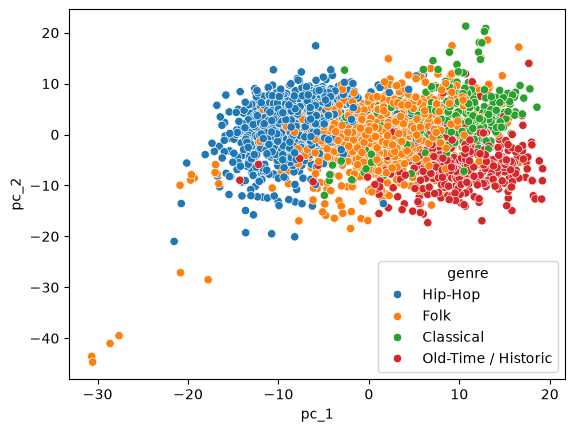

In [9]:
sns.scatterplot(x ='pc_1', y = 'pc_2', data=pca, hue=y) # Ого, получилось

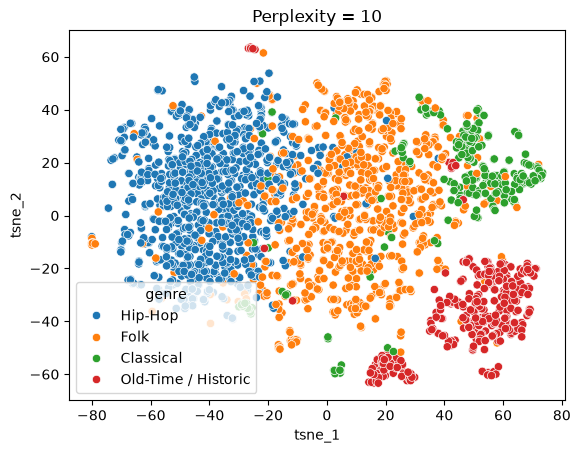

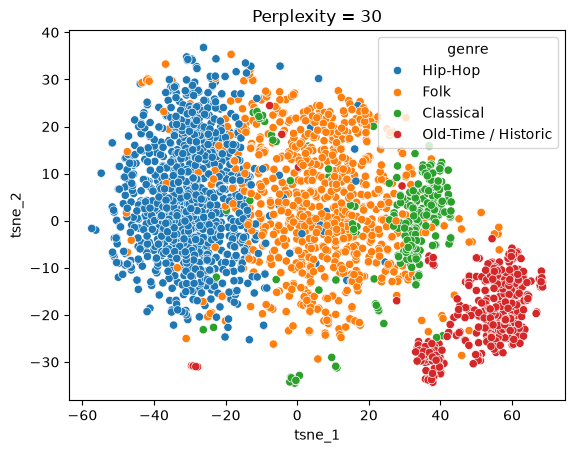

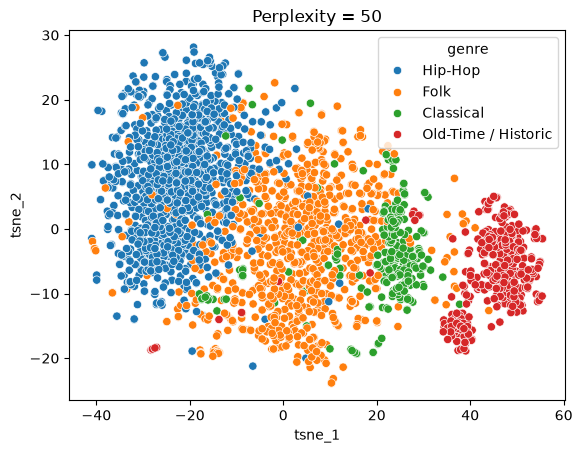

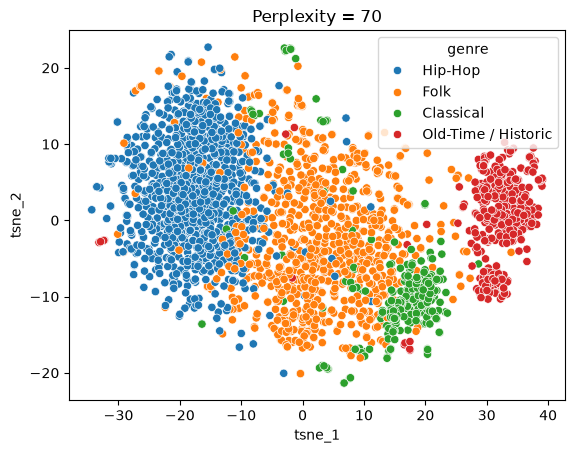

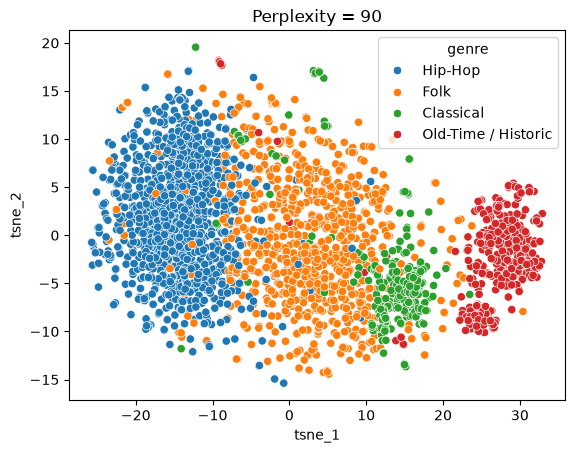

In [10]:
for i in range(1, 11, 2):
    tsne = TSNE(perplexity=i*10).fit_transform(x)
    tsne = pd.DataFrame(tsne, columns=['tsne_1', 'tsne_2'])
    sns.scatterplot(x = 'tsne_1', y = 'tsne_2', data=tsne, hue=y)
    plt.title('Perplexity = {0}'.format(i*10))
    plt.show()

In [11]:
from sklearn import decomposition
pca = decomposition.PCA()

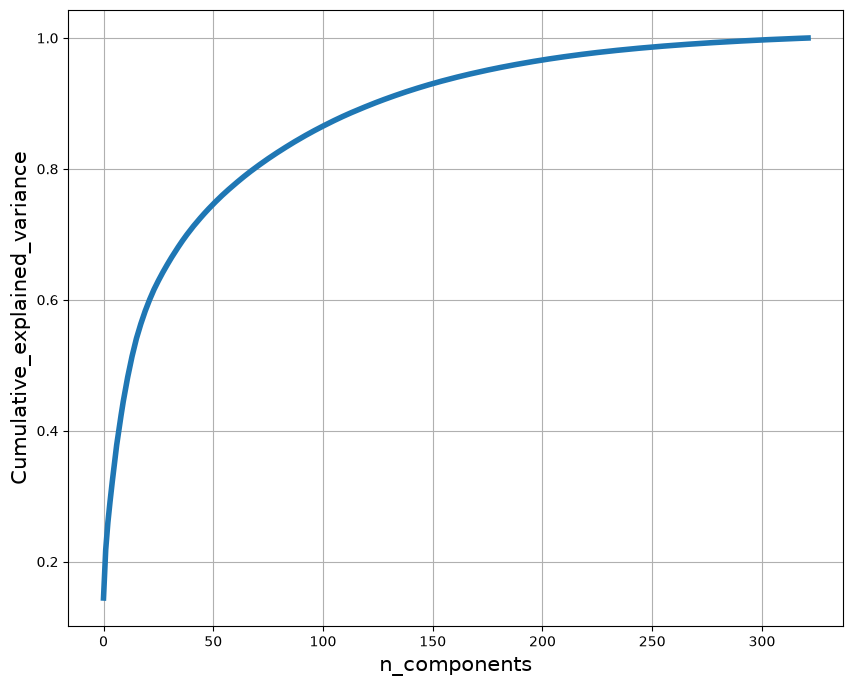

2D -  0.2601056058954813
200D -  0.9664284025530224


In [12]:
pca.n_components = 322
pca_data = pca.fit_transform(x)

percentage_var_explained = pca.explained_variance_ / np.sum(pca.explained_variance_);

cum_var_explained = np.cumsum(percentage_var_explained)

plt.figure(figsize=(10, 8))
plt.plot(cum_var_explained, linewidth=4)
plt.axis('tight')
plt.grid()
plt.xlabel('n_components', size=15)
plt.ylabel('Cumulative_explained_variance', size=15)
plt.show()

print("2D - ", cum_var_explained[2])
print("200D - ",cum_var_explained[200]) # метод хорошо работает, при повышении измерения повышается объяснение дисперсии

In [13]:
print(cum_var_explained[321])

0.9999999999999994


In [14]:

km = KMeans(n_clusters=4, n_init=1, max_iter=10, random_state=42, init='random') #n_clusters - количество жанров
km.fit(x)
# А как это лучше визуализировать? Я боролся с этим долго, брал за пример вашу работу с Kmeans, но там визуализация идет по осям x и y, которые там очевидны. А тут? Или с PCA и t-sne было достаточно?

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 522)","[[ 0.03,

In [15]:
from sklearn.metrics import silhouette_score, rand_score

In [16]:
labels = km.fit_predict(x)
print('silhouette_score - ', silhouette_score(x, labels)) #Почему так мало? 500+ мерное пространство и должно занижать оценку, rand_score показывает неплохой результат
print('rand_score - ', rand_score(y, labels))

silhouette_score -  0.0679418242426634
rand_score -  0.7625278453208628


In [17]:
from sklearn.metrics import adjusted_rand_score

In [18]:
print("adjusted_rand_score - ", adjusted_rand_score(y, labels))

adjusted_rand_score -  0.4409750955416615


In [19]:
print(y.nunique())

4


In [20]:
for i in range(2, 7):
    km = KMeans(n_clusters=i, n_init=1, max_iter=10, random_state=42, init='random') #n_clusters - количество жанров(вообще их 4)
    km.fit(x)
    labels = km.fit_predict(x)
    print('n_clusters = ', i, ' silhouette_score - ', silhouette_score(x, labels), 'rand_score - ', rand_score(y, labels))

n_clusters =  2  silhouette_score -  0.10957605145660479 rand_score -  0.6803386544034923
n_clusters =  3  silhouette_score -  0.080065509735892 rand_score -  0.676821114227598
n_clusters =  4  silhouette_score -  0.0679418242426634 rand_score -  0.7625278453208628
n_clusters =  5  silhouette_score -  0.03435579381217055 rand_score -  0.7775671700858733
n_clusters =  6  silhouette_score -  0.03690910047593285 rand_score -  0.7595460413415526


# Ответы и вывод
## 6.1 Они отражают примерное распределение жанров. PCA - быстрый метод сжатия данных, с сохранением общей структуры, t-SNE для 2D или 3D визуализации. Мне больше понравился t-SNE, он более наглядный и удобнее для восприятия

## 6.2 2D - 0.2601027638394619 если быть совсем точным, т.е. такой процент исходных признаков сохраняет компонента

## 6.3 Ну конечно rand_score лучше, потому что у меня на нем лучше показатель:) rand_score показывает насколько правильно Kmeans сгруппировал объекты, Silhouette на геометрию, т.к. на каждый объект по 500 признаков, и Silhouette из-за этого занижается(значит ли это, что его нельзя использовать при большом количестве признаков?)

## 6.4 Ответ исходит из пункта 6.3. Рекомендательная система предлагала бы песни одного и того же класса(приоритет не геометрическое расстояние между объектами, т.к. оно здесь не работает, а соответствие классу)

## 6.5 В зависимости от задачи:) Рекомендательная система могла бы и предлагать песни по длине, я же пошел через жанр песней.